# MODIS-Aqua L2 vs. DBO chem-log chlorophyll match-ups (Bailey & Werdell)

Validate the MODIS-Aqua operational chlorophyll product (`chlor_a`) against in-situ
**extracted Chl-*a*** from the SWL/DBO **chem-log** bottle files, for every year with data.

**Method** — match-ups follow the protocol of
**Bailey, S.W. & Werdell, P.J. (2006), *A multi-sensor approach for the on-orbit validation of
ocean color satellite data products*, Remote Sensing of Environment 102:12–23**:

1. For each in-situ station take the **shallowest bottle nearest 5 m** (depth from CTD pressure).
2. Find the MODIS-Aqua **L2** granule(s) within the time window of the cast.
3. Extract a **5 × 5 pixel box** centred on the pixel nearest the station.
4. **Exclude** pixels flagged by the standard OBPG L2 ocean-color masks, or non-positive `chlor_a`.
5. Require **> 50 %** of the box pixels valid, and **coefficient of variation (CV) ≤ 0.15**.
6. Compute the **filtered mean** (drop pixels outside mean ± 1.5 σ, recompute) → the satellite value.
7. Regress satellite vs. in-situ Chl-*a* in **log₁₀** space and report validation statistics.

> We use **L2** (not the L3 mapped product in `02_modis-chlor-a-daily-ease2.ipynb`) because per-pixel
> `l2_flags` and ~1 km native pixels are what the Bailey & Werdell box statistics require.

All tunable parameters live in the **CONFIG** cell so you can widen the time window etc.


In [3]:
import os, re, pickle, warnings
from pathlib import Path
from datetime import timedelta

import numpy as np
import pandas as pd
import xarray as xr
import earthaccess
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 80)

## CONFIG — paths and Bailey & Werdell parameters

In [4]:
# ---- paths -----------------------------------------------------------------
CHEM_DIR      = Path.home() / "chemlogs"  # add your path
OUT_DIR       = Path.home() / "modis_l2_chl_matchups"     # results + downloaded granules  # add your path
GRANULE_CACHE = OUT_DIR / "granules"
OUT_DIR.mkdir(parents=True, exist_ok=True)
GRANULE_CACHE.mkdir(parents=True, exist_ok=True)

# ---- in-situ surface sampling ---------------------------------------------
TARGET_DEPTH_M = 5.0     # B&W surface target; for the upper ocean pressure(db) ~= depth(m)
MAX_SURFACE_DB = 10.0    # reject a cast if its shallowest usable bottle is deeper than this
CHL_MIN, CHL_MAX = 0.0, 100.0   # plausible extracted-chl bounds (mg m^-3 == ug/L)

# ---- MODIS L2 product ------------------------------------------------------
MODIS_SHORT_NAME = "MODISA_L2_OC"   # MODIS-Aqua L2 Ocean Color (chlor_a, l2_flags, navigation)

# ---- Bailey & Werdell (2006) match-up protocol -----------------------------
BOX_SIZE          = 5      # N x N extraction box centred on nearest pixel (B&W = 5 -> 25 px)
TIME_WINDOW_HOURS = 12.0    # |t_insitu - t_overpass| <= this. B&W = 3 h; widen if too few match-ups
MIN_VALID_FRAC    = 0.50   # require strictly > this fraction of box pixels valid (B&W: > 50%)
FILTER_SIGMA      = 1.5    # drop pixels outside mean +/- this*std, then recompute the mean
MAX_CV            = 0.15   # CV (std/mean) of valid pixels must be <= this (spatial homogeneity)
MAX_PIX_DIST_KM   = 2.0    # nearest pixel must be within this of the station (else not in swath)
BBOX_HALF_DEG     = 0.20   # half-width of the granule search box around each station (deg)
MAX_CANDIDATES    = 8      # cap granules evaluated per station (sorted by |dt|)

# In-situ timestamps are UTC for these cruises (2017 sheet header is 'Cast Start Time [UTC]').
# Set this if a given year's DATE were logged in ship-local time.
INSITU_TZ_OFFSET_HOURS = 0.0

LAT_MIN_FILTER = None      # set e.g. 60.0 to keep only Arctic stations; None keeps all
RECOMPUTE      = False     # True ignores the on-disk match-up cache and redoes everything

# Standard OBPG L2 ocean-color exclusion flags (default chlor_a masking). A box pixel is
# rejected if ANY of these l2_flags bits is set. Bits are read from the file's attributes.
EXCLUDE_FLAGS = [
    "ATMFAIL", "LAND", "HIGLINT", "HILT", "HISATZEN", "STRAYLIGHT", "CLDICE",
    "COCCOLITH", "HISOLZEN", "LOWLW", "CHLFAIL", "NAVWARN", "MAXAERITER",
    "CHLWARN", "NAVFAIL", "FILTER",
]

## Part A — Build the in-situ surface Chl-*a* table from the chem-logs

The chem-log exports drifted in schema from year to year, so each year is mapped to its file
and the extracted-Chl-*a* column is resolved by priority. 2017 uses its own bottle file
(`SirWilfridLaurier2017_Bottle_data.csv`) with a cleaner, differently-named schema.

In [5]:
# Per-year sources. CSV years are ODV bottle exports (first line is a title -> skiprows=1).
CSV_FILES = {
    2013: "ODV5_ChemLog2013_hy1.csv",
    2014: "ODV5_ChemLog2014_hy1.csv",
    2015: "ODV4_ChemLog2015_hy1.csv",
    2016: "ODV4_ChemLog2016_hy1.csv",
    2018: "ODV5_ChemLog2018_hy1.csv",
    2019: "ODV_ChemLog2019_hy1.csv",
    2021: "2021-014_SWL_Chem_hy1_VALID_v3.csv",
    2022: "2022-041_SWL_Chem_ABwk_hy1_ALLDATA_FIXED.csv",
    2023: "2023-016_SWL_ChemAB_hy1_ALLDATA_FIXEDNUM_with_CTDPRS.csv",
}
# 2017 and 2024 are their own bottle files with distinct schemas. Looked up in CHEM_DIR.
FILE_2017    = "SirWilfridLaurier2017_Bottle_data.csv"
CHL_COL_2017 = "Chl_a_Frey"   # Frey extracted Chl-a (consistent w/ other years; 'chla' = UMCES onboard)
FILE_2024    = "Sikuliaq2024_BottleData_v2.csv"   # SKQ202412S cruise
CHL_COL_2024 = "chla"         # only extracted-chl column in this file

# Preferred extracted Chl-a column, by priority. Frey-lab extracted Chl-a is the most consistent
# series across years; fall back to onboard UMCES, then total chlorophyll.
CHL_PRIORITY = [
    "Chl-a (ug/L)",
    "Frey Chl-a (ug/L)",
    "chla [ug/L] (Anal. Onboard by UMCES )",
    "chla (values)",
    "ChlTOT-1 [ug/L]",
    "ChlTOT-1 [ug/L] (Anal. @ UMCES )",
]
MISSING_SENTINELS = [-9.0, -99.0, -999.0, 1e-12]

In [6]:
def _read_csv_any(path):
    for enc in ("utf-8", "latin-1"):          # 2014-2016 & 2018 are Windows-1252 encoded
        try:
            return pd.read_csv(path, skiprows=1, low_memory=False, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise IOError(f"could not decode {path}")

def _num(s):
    v = pd.to_numeric(s, errors="coerce")
    return v.mask(v.isin(MISSING_SENTINELS))

def load_csv_year(year, fname):
    df = _read_csv_any(CHEM_DIR / fname)
    df.columns = [str(c) for c in df.columns]
    cols = list(df.columns)
    chl_col = next((c for c in CHL_PRIORITY if c in cols), None)
    if chl_col is None:
        print(f"  [{year}] no recognised chl column -> skipped"); return None
    chl = _num(df[chl_col])
    if chl.gt(0).sum() == 0:
        print(f"  [{year}] chl column '{chl_col}' is empty -> skipped"); return None
    prs_col = "CTDPRS [db]" if "CTDPRS [db]" in cols else ("Raw Pres [dbar]" if "Raw Pres [dbar]" in cols else None)
    out = pd.DataFrame({
        "year": year,
        "cruise":  df.get("EXPOCODE", pd.Series([str(year)] * len(df))).astype(str),
        "station": df.get("STNNBR",   pd.Series([""] * len(df))).astype(str),
        "cast":    df.get("CASTNO",   pd.Series([np.nan] * len(df))),
        "datetime_raw": df.get("DATE", pd.Series([None] * len(df))),
        "lat": _num(df["LATITUDE"]),
        "lon": _num(df["LONGITUDE"]),
        "pressure_db": _num(df[prs_col]) if prs_col else np.nan,
        "chl_insitu": chl,
        "chl_col": chl_col,
    })
    return out

def _resolve(fname):
    for d in (CHEM_DIR,):  # add your path
        if (d / fname).exists():
            return d / fname
    raise FileNotFoundError(f"{fname} not found in {CHEM_DIR}")

def load_2017_csv(fname=FILE_2017, chl_col=CHL_COL_2017):
    df = pd.read_csv(_resolve(fname), low_memory=False)
    df.columns = [str(c).strip() for c in df.columns]    # 'CTDPres_dbar ' carries a trailing space
    return pd.DataFrame({
        "year": 2017,
        "cruise":  df["CruiseID"].astype(str),
        "station": df["StationName"].astype(str),
        "cast":    df["Cast_No"],
        "datetime_raw": df["CastStartTime_UTC"],   # already UTC
        "lat": _num(df["Latitude"]),
        "lon": _num(df["Longitude"]),              # already signed
        "pressure_db": _num(df["CTDPres_dbar"]),
        "chl_insitu": _num(df[chl_col]),
        "chl_col": chl_col,
    })

def load_2024_csv(fname=FILE_2024, chl_col=CHL_COL_2024):
    df = pd.read_csv(_resolve(fname), low_memory=False)
    df.columns = [str(c).strip() for c in df.columns]
    return pd.DataFrame({
        "year": 2024,
        "cruise":  df["CruiseID"].astype(str),
        "station": df["StationNme"].astype(str),
        "cast":    df["Cast_Number"],
        "datetime_raw": df["DataDate"],           # YYYYMMDD, date-only -> whole-day matching
        "lat": _num(df["Latitude"]),
        "lon": _num(df["Longitude"]),             # already signed
        "pressure_db": _num(df["Pres_dbar"]),
        "chl_insitu": _num(df[chl_col]),
        "chl_col": chl_col,
    })

In [7]:
# ---- load every year, stack, parse datetimes -------------------------------
frames = []
for yr, fn in sorted(CSV_FILES.items()):
    f = load_csv_year(yr, fn)
    if f is not None:
        frames.append(f)
frames.append(load_2017_csv())
frames.append(load_2024_csv())
raw = pd.concat(frames, ignore_index=True)

def parse_dt_series(s):
    txt = s.astype("string")
    txt = txt.str.replace(r"^(\d{8})\.0$", r"\1", regex=True)        # 20160712.0 -> 20160712
    out = pd.to_datetime(txt, errors="coerce", format="mixed", dayfirst=False)
    m = out.isna() & txt.str.fullmatch(r"\d{8}")                     # bare YYYYMMDD (2016, 2018)
    if m.any():
        out = out.copy(); out[m] = pd.to_datetime(txt[m], format="%Y%m%d", errors="coerce")
    return out

raw["datetime"] = parse_dt_series(raw["datetime_raw"])
raw["datetime"] = raw["datetime"] - pd.to_timedelta(INSITU_TZ_OFFSET_HOURS, unit="h")

# A bare midnight stamp means the source had a date but no time -> use a whole-day window later.
t = raw["datetime"]
raw["time_known"] = t.notna() & ~((t.dt.hour == 0) & (t.dt.minute == 0) & (t.dt.second == 0))

print(f"{len(raw):,} raw bottle rows across {raw['year'].nunique()} years")
print(raw.groupby("year").agg(rows=("chl_insitu", "size"),
                              chl_obs=("chl_insitu", lambda s: s.gt(0).sum()),
                              chl_col=("chl_col", "first")))

6,621 raw bottle rows across 11 years
      rows  chl_obs            chl_col
year                                  
2013   262      136       Chl-a (ug/L)
2014   276      182       Chl-a (ug/L)
2015   424      219       Chl-a (ug/L)
2016   312      173       Chl-a (ug/L)
2017   548      244         Chl_a_Frey
2018   468      193       Chl-a (ug/L)
2019   647      184       Chl-a (ug/L)
2021  1343      227       Chl-a (ug/L)
2022   805      188  Frey Chl-a (ug/L)
2023   756      197  Frey Chl-a (ug/L)
2024   780      240               chla


In [8]:
# ---- one surface value per cast: shallowest bottle nearest 5 m -------------
def pick_surface(g):
    d = g.dropna(subset=["pressure_db", "chl_insitu", "lat", "lon", "datetime"])
    d = d[(d["chl_insitu"] > CHL_MIN) & (d["chl_insitu"] <= CHL_MAX) & (d["pressure_db"] >= 0)]
    if d.empty:
        return None
    d = d.assign(ddepth=(d["pressure_db"] - TARGET_DEPTH_M).abs())
    best = d.sort_values("ddepth").iloc[0]
    if best["pressure_db"] > MAX_SURFACE_DB:      # nothing shallow enough at this station
        return None
    return best

records = []
for key, g in raw.groupby(["year", "cruise", "station", "datetime"], dropna=False):
    b = pick_surface(g)
    if b is None:
        continue
    records.append({
        "year": int(b["year"]), "cruise": b["cruise"], "station": b["station"],
        "datetime": b["datetime"], "time_known": bool(b["time_known"]),
        "lat": float(b["lat"]), "lon": float(b["lon"]),
        "pressure_db": float(b["pressure_db"]), "chl_insitu": float(b["chl_insitu"]),
    })

insitu = pd.DataFrame(records).sort_values(["year", "datetime"]).reset_index(drop=True)
if LAT_MIN_FILTER is not None:
    insitu = insitu[insitu["lat"] >= LAT_MIN_FILTER].reset_index(drop=True)
insitu["uid"] = (insitu["year"].astype(str) + "_" + insitu.index.astype(str))

insitu.to_csv(OUT_DIR / "insitu_surface_chl.csv", index=False)
print(f"{len(insitu)} surface stations with extracted Chl-a")
print(insitu.groupby("year").agg(stations=("chl_insitu", "size"),
                                 chl_median=("chl_insitu", "median"),
                                 mean_pres_db=("pressure_db", "mean")).round(2))
insitu.head()

398 surface stations with extracted Chl-a
      stations  chl_median  mean_pres_db
year                                    
2013        26        6.68          5.08
2014        34        0.46          5.02
2015        41        0.26          5.31
2016        34        0.42          4.82
2017        45        0.41          5.11
2018        35        0.56          5.37
2019        31        0.67          5.09
2021        40        0.78          4.96
2022        34        0.74          5.31
2023        36        0.95          5.03
2024        42        0.63          3.15


,year,cruise,station,datetime,time_known,lat,lon,pressure_db,chl_insitu,uid
0,2013,2013-05,SLIP-1,2013-07-14 04:05:00,True,62.0100,-175.0595,5.654,3.910000,2013_0
1,2013,2013-05,SLIP-3,2013-07-14 10:17:00,True,62.3907,-174.5706,5.286,0.806667,2013_1
2,2013,2013-05,SLIP-5,2013-07-14 14:38:00,True,62.5601,-173.5498,5.444,2.470000,2013_2
3,2013,2013-05,SLIP-4,2013-07-14 18:42:00,True,63.0304,-173.4597,4.922,11.512500,2013_3
4,2013,2013-05,UTBS-5,2013-07-15 09:57:00,True,64.6710,-169.9209,4.764,8.496667,2013_4


## Part B — MODIS-Aqua L2 match-ups

Log in to NASA Earthdata (uses your `~/.netrc` / cached token, same as your other notebooks),
then confirm the L2 ocean-color short name is available.

In [9]:
auth = earthaccess.login(persist=True)

# Confirm the product short name (run once; comment out afterwards)
for c in earthaccess.search_datasets(keyword="MODIS Aqua L2 ocean color chlorophyll")[:8]:
    print(f"{c['umm']['ShortName']:24s} | {c['umm'].get('EntryTitle','')}")

MODISA_L2_OC             | Aqua MODIS Level-2 Regional  Ocean Color (OC) Data, version 2022.0
MODISA_L2_OC_NRT         | Aqua MODIS Level-2 Regional  Ocean Color (OC) - Near Real-time (NRT) Data, version 2022.0
WEBCOAST_US_MOD_SST-CHL  | MODIS Aggregate for the Gulf of Maine; MODIS Ocean Products SST and Chlorophyll-a 8-Day L2 Global 1.25 km Lambert Grid, DOY: 305, 2000 to present
gov.noaa.nodc:CoastWatch-OC-Frontal | NOAA CoastWatch Chlorophyll Frontal Product from MODIS/Aqua


In [16]:
# ---- Bailey & Werdell box machinery ---------------------------------------
def build_flag_bitmask(l2_flags_var, names):
    masks    = np.asarray(l2_flags_var.attrs["flag_masks"]).astype("int64")
    meanings = str(l2_flags_var.attrs["flag_meanings"]).split()
    name2mask = dict(zip(meanings, masks))
    bits, missing = 0, []
    for n in names:
        if n in name2mask:
            bits |= int(name2mask[n])
        else:
            missing.append(n)
    return bits, missing

def haversine_km(lat1, lon1, lat2, lon2):
    R, p = 6371.0, np.pi / 180.0
    dlat, dlon = (lat2 - lat1) * p, (lon2 - lon1) * p
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def open_l2(path):
    geo = xr.open_dataset(path, group="geophysical_data", engine="h5netcdf")
    nav = xr.open_dataset(path, group="navigation_data", engine="h5netcdf")
    chl   = geo["chlor_a"].values.astype("float64")
    flags = geo["l2_flags"].values.astype("int64")
    fbits, missing = build_flag_bitmask(geo["l2_flags"], EXCLUDE_FLAGS)
    latg = nav["latitude"].values.astype("float64")
    long = nav["longitude"].values.astype("float64")
    geo.close(); nav.close()
    return latg, long, chl, flags, fbits, missing

def extract_matchup(lat0, lon0, latg, long, chl, flags, fbits):
    near = (np.abs(latg - lat0) < 0.25) & (np.abs(long - lon0) < 0.5)
    if not near.any():
        return {"status": "not_in_swath"}
    ii, jj = np.where(near)
    d = haversine_km(lat0, lon0, latg[ii, jj], long[ii, jj])
    k = int(np.argmin(d)); i0, j0, dmin = int(ii[k]), int(jj[k]), float(d[k])
    if dmin > MAX_PIX_DIST_KM:
        return {"status": "too_far", "dist_km": dmin}
    h = BOX_SIZE // 2
    if i0 - h < 0 or j0 - h < 0 or i0 + h >= chl.shape[0] or j0 + h >= chl.shape[1]:
        return {"status": "box_off_edge", "dist_km": dmin}
    cbox = chl[i0 - h:i0 + h + 1, j0 - h:j0 + h + 1]
    fbox = flags[i0 - h:i0 + h + 1, j0 - h:j0 + h + 1]
    valid = np.isfinite(cbox) & (cbox > 0) & ((fbox & fbits) == 0)
    n_box, n_valid = cbox.size, int(valid.sum())
    base = {"dist_km": dmin, "n_box": n_box, "n_valid": n_valid,
            "center_i": i0, "center_j": j0}
    if n_valid <= MIN_VALID_FRAC * n_box:                  # B&W: need strictly > 50% valid
        return {"status": "too_few_valid", **base}
    v = cbox[valid]
    mean0, std0 = float(v.mean()), float(v.std(ddof=0))
    cv = std0 / mean0 if mean0 > 0 else np.inf
    keep = np.abs(cbox - mean0) <= FILTER_SIGMA * std0     # +/-1.5 sigma filter, recompute mean
    fv = cbox[valid & keep]
    sat = float(fv.mean()) if fv.size else mean0
    status = "ok" if cv <= MAX_CV else "high_cv"
    return {"status": status, "sat_chl": sat, "sat_chl_unfiltered": mean0,
            "sat_chl_median": float(np.median(v)), "cv": cv, "n_filtered": int(fv.size), **base}

def granule_mid_time(g):
    rt = g["umm"]["TemporalExtent"]["RangeDateTime"]
    a = pd.to_datetime(rt["BeginningDateTime"]).tz_localize(None)
    b = pd.to_datetime(rt["EndingDateTime"]).tz_localize(None)
    return a + (b - a) / 2

In [17]:
# ---- main match-up loop (cached + resumable) ------------------------------
CACHE_PKL = OUT_DIR / "matchup_cache.pkl"
cache = {} if (RECOMPUTE or not CACHE_PKL.exists()) else pickle.load(open(CACHE_PKL, "rb"))
# Transient failures (code/read/search errors) are not final -> drop them so they get retried.
# Legitimate outcomes (ok, no_granule, too_few_valid, high_cv, too_far, box_off_edge) stay cached.
cache = {u: r for u, r in cache.items()
         if not str(r.get("status", "")).startswith(("read_err", "search_err"))}

results = []
for n, row in enumerate(insitu.itertuples(index=False), 1):
    uid = row.uid
    if uid in cache:
        results.append(cache[uid]); continue

    lat0, lon0, t_is = row.lat, row.lon, row.datetime
    if row.time_known:
        t0, t1 = t_is - pd.Timedelta(hours=TIME_WINDOW_HOURS), t_is + pd.Timedelta(hours=TIME_WINDOW_HOURS)
    else:                                       # date-only station -> whole UTC day
        t0 = t_is.normalize(); t1 = t0 + pd.Timedelta(hours=24)

    rec = {"uid": uid, "year": row.year, "station": row.station, "datetime": t_is,
           "lat": lat0, "lon": lon0, "chl_insitu": row.chl_insitu,
           "time_known": row.time_known, "status": "no_granule", "sat_chl": np.nan}
    try:
        grans = earthaccess.search_data(
            short_name=MODIS_SHORT_NAME,
            temporal=(t0.strftime("%Y-%m-%dT%H:%M:%S"), t1.strftime("%Y-%m-%dT%H:%M:%S")),
            bounding_box=(lon0 - BBOX_HALF_DEG, lat0 - BBOX_HALF_DEG,
                          lon0 + BBOX_HALF_DEG, lat0 + BBOX_HALF_DEG))
    except Exception as e:
        grans = []; rec["status"] = f"search_err:{str(e)[:50]}"

    if grans:
        grans = sorted(grans, key=lambda g: abs((granule_mid_time(g) - t_is).total_seconds()))[:MAX_CANDIDATES]
        best, fallback = None, None
        for g in grans:
            gt = granule_mid_time(g); dt_h = (gt - t_is).total_seconds() / 3600.0
            if row.time_known and abs(dt_h) > TIME_WINDOW_HOURS:
                continue
            try:
                path = earthaccess.download([g], str(GRANULE_CACHE))[0]
                m = extract_matchup(lat0, lon0, *open_l2(path)[:5])   # drop the 'missing' diagnostic
            except Exception as e:
                m = {"status": f"read_err:{str(e)[:50]}"}
            cand = {**m, "dt_hours": dt_h, "granule": g["umm"]["GranuleUR"], "sat_time": gt}
            if cand["status"] == "ok":
                if best is None or abs(dt_h) < abs(best["dt_hours"]):
                    best = cand
            elif fallback is None:
                fallback = cand
        if best is not None:
            rec.update(best)
        elif fallback is not None:
            rec.update({k: fallback.get(k) for k in ("status", "dt_hours", "granule", "cv",
                                                     "n_valid", "n_box", "dist_km")})

    cache[uid] = rec; results.append(rec)
    if n % 10 == 0 or n == len(insitu):
        pickle.dump(cache, open(CACHE_PKL, "wb"))
        nok = sum(1 for r in results if r.get("status") == "ok")
        print(f"  {n}/{len(insitu)} stations processed — {nok} match-ups so far")
pickle.dump(cache, open(CACHE_PKL, "wb"))

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

... (7,017 outputs left out)

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

  398/398 stations processed — 48 match-ups so far


In [19]:
# ---- assemble + save -------------------------------------------------------
mdf = pd.DataFrame(results)
matched = mdf[mdf["status"] == "ok"].copy()

mdf.to_csv(OUT_DIR / "modis_l2_chl_matchups_all_attempts.csv", index=False)
matched.to_csv(OUT_DIR / "modis_l2_chl_matchups.csv", index=False)

print("Outcome of every station:")
print(mdf["status"].value_counts(), "\n")
print(f"{len(matched)} valid match-ups out of {len(mdf)} stations\n")
print("Valid match-ups per year:")
print(matched.groupby("year").agg(n=("sat_chl", "size"),
                                  insitu_med=("chl_insitu", "median"),
                                  modis_med=("sat_chl", "median")).round(3))
matched[["year", "station", "datetime", "chl_insitu", "sat_chl", "cv",
         "n_valid", "dt_hours", "dist_km"]].head(20)

Outcome of every station:
status
too_few_valid    329
ok                48
too_far           11
high_cv            4
box_off_edge       3
not_in_swath       3
Name: count, dtype: int64 

48 valid match-ups out of 398 stations

Valid match-ups per year:
       n  insitu_med  modis_med
year                           
2015   8       0.645      0.283
2016   2       0.667      0.819
2018  23       0.899      1.597
2019   4       1.268      1.578
2022   3       0.181      0.630
2023   4       0.746      1.205
2024   4       0.975      0.959


,year,station,datetime,chl_insitu,sat_chl,cv,n_valid,dt_hours,dist_km
60,2015,SLIP-1,2015-07-14 14:18:29,0.060000,0.273217,0.047232,25.0,9.483750,0.268496
61,2015,SLIP-2,2015-07-14 17:07:04,0.100000,0.290758,0.039374,25.0,6.674028,0.689356
62,2015,SLIP-3,2015-07-14 21:38:27,0.070000,0.274849,0.024390,25.0,2.150972,0.135414
63,2015,SLIP-5,2015-07-15 02:16:47,1.550000,0.246155,0.018819,25.0,-2.487917,0.614445
64,2015,SLIP-4,2015-07-15 06:27:29,0.010000,0.220329,0.015296,25.0,-6.666250,0.411142
69,2015,UTBS-1,2015-07-16 11:44:56,1.190000,1.792999,0.145120,25.0,11.875972,0.598583
81,2015,UTN-6,2015-07-18 04:56:07,8.290000,1.906624,0.086647,13.0,-6.226806,0.472020
82,2015,SEC-2,2015-07-18 06:21:03,10.210000,1.702399,0.137081,19.0,-7.642361,0.436035
117,2016,UTN-1,2016-07-15 00:00:00,0.859000,1.107344,0.064572,25.0,23.125000,0.655694
130,2016,UTN-7,2016-07-17 00:00:00,0.475000,0.529983,0.031524,25.0,22.875000,0.630858


## Part C — Regression and validation statistics

Ocean-color validation convention: compare in **log₁₀** space and report
N, R², RMSE, bias and the Type-II (RMA) regression. RMSE here is in log₁₀ units, directly
comparable to the values you track elsewhere (e.g. Dawson ≈ 0.16).

In [20]:
def validation_stats(insitu_v, sat_v):
    insitu_v, sat_v = np.asarray(insitu_v, float), np.asarray(sat_v, float)
    m = np.isfinite(insitu_v) & np.isfinite(sat_v) & (insitu_v > 0) & (sat_v > 0)
    x, y = np.log10(insitu_v[m]), np.log10(sat_v[m])
    n = len(x)
    if n < 3:
        return {"N": n}
    r = np.corrcoef(x, y)[0, 1]
    sx, sy = x.std(ddof=1), y.std(ddof=1)
    slope = np.sign(np.cov(x, y)[0, 1]) * sy / sx          # RMA / geometric-mean (Type II)
    intercept = y.mean() - slope * x.mean()
    return {
        "N": n, "R2": r ** 2,
        "RMSE_log10": float(np.sqrt(np.mean((y - x) ** 2))),
        "bias_log10": float(np.mean(y - x)),
        "MAE_log10":  float(np.mean(np.abs(y - x))),
        "RMA_slope": float(slope), "RMA_intercept": float(intercept),
        "MdAPD_pct": float(np.median(np.abs(sat_v[m] - insitu_v[m]) / insitu_v[m]) * 100),
        "median_ratio": float(np.median(sat_v[m] / insitu_v[m])),
    }

stats_all = validation_stats(matched["chl_insitu"], matched["sat_chl"])
print("Overall MODIS-Aqua vs in-situ (log10 space):")
for k, v in stats_all.items():
    print(f"  {k:14s}: {v:.4f}" if isinstance(v, float) else f"  {k:14s}: {v}")

Overall MODIS-Aqua vs in-situ (log10 space):
  N             : 48
  R2            : 0.4963
  RMSE_log10    : 0.4389
  bias_log10    : 0.1773
  MAE_log10     : 0.3476
  RMA_slope     : 0.5385
  RMA_intercept : 0.1143
  MdAPD_pct     : 78.3015
  median_ratio  : 1.3635


In [24]:
# ── Optical-depth-weighted in-situ chl (Gordon & Clark 1980), per matchup ──────────
# Rebuild the FULL profile for each cast from the raw bottles, then weight by exp(-2*Kd*z).

def clean_profile(g):
    d = g.dropna(subset=["pressure_db", "chl_insitu"])
    d = d[(d["chl_insitu"] > CHL_MIN) & (d["chl_insitu"] <= CHL_MAX) & (d["pressure_db"] >= 0)]
    d = d.groupby("pressure_db", as_index=False)["chl_insitu"].mean().sort_values("pressure_db")
    return d["pressure_db"].values, d["chl_insitu"].values          # z (m ~ dbar), chl(z)

profiles = {}
for key, g in raw.groupby(["year", "cruise", "station", "datetime"], dropna=False):
    z, chl = clean_profile(g)
    if z.size >= 1:
        profiles[key] = (z, chl)
nmulti = sum(1 for z, _ in profiles.values() if z.size >= 2)
print(f"{len(profiles)} casts | {nmulti} have >=2 chl depths (weighting only changes these)")

def kd490_from_chl(chl):
    # Morel et al. (2007) case-1 Kd(490); approximate in Arctic Case-2 water (see caveat)
    return 0.0166 + 0.0773 * np.asarray(chl, float) ** 0.6715

def optical_weighted(z, chl, kd490):
    z, chl = np.asarray(z, float), np.asarray(chl, float)
    m = np.isfinite(z) & np.isfinite(chl)
    if m.sum() == 0:
        return np.nan
    w = np.exp(-2.0 * kd490 * z[m])                                 # Gordon & Clark weight
    return float(np.sum(w * chl[m]) / np.sum(w))

# map each matchup (uid) back to its cast profile via the insitu table's keys
key_cols = ["year", "cruise", "station", "datetime"]
uid2key = insitu.set_index("uid")[key_cols].to_dict("index")

rows = []
for r in matched.itertuples(index=False):
    k = uid2key.get(r.uid)
    prof = profiles.get((k["year"], k["cruise"], k["station"], k["datetime"])) if k else None
    if prof is None:
        continue
    z, chl = prof
    kd = float(kd490_from_chl(r.sat_chl))                           # Kd(490) from the satellite chl
    rows.append({"uid": r.uid, "chl_weighted": optical_weighted(z, chl, kd),
                 "n_depths": int(z.size), "z_min_m": float(z.min()),
                 "z_max_m": float(z.max()), "kd490": kd})
matched_w = matched.merge(pd.DataFrame(rows), on="uid", how="left")

print(matched_w[["station", "chl_insitu", "chl_weighted", "n_depths",
                 "z_min_m", "z_max_m", "sat_chl"]].round(3).head(15).to_string(index=False))


409 casts | 405 have >=2 chl depths (weighting only changes these)
       station  chl_insitu  chl_weighted  n_depths  z_min_m  z_max_m  sat_chl
        SLIP-1       0.060         0.096         6    6.119   72.633    0.273
        SLIP-2       0.100         0.141         7    5.420   78.549    0.291
        SLIP-3       0.070         0.089         6    5.299   65.564    0.275
        SLIP-5       1.550         0.959         6    5.591   60.689    0.246
        SLIP-4       0.010         0.023         6    5.409   62.150    0.220
        UTBS-1       1.190         1.169         4    5.188   44.201    1.793
         UTN-6       8.290         8.189         5    5.003   43.388    1.907
         SEC-2      10.210         9.634         5    4.980   44.131    1.702
         UTN-1       0.859         0.856         4    4.981   30.025    1.107
         UTN-7       0.475         3.195         6    4.478   52.606    0.530
 SLIP-1/DBO1.1       0.268         0.651         7    5.600   75.500    0.3

In [26]:
# ── Re-open each matchup's cached granule; pull box-median Kd_490 + Rrs bands ────────
def _granule_path(ur):
    ur = str(ur); p = GRANULE_CACHE / ur
    if p.exists(): return str(p)
    for f in GRANULE_CACHE.glob("*.nc"):
        if f.name == ur or f.stem in ur or ur in f.name: return str(f)
    hits = list(GRANULE_CACHE.glob(ur.split(".")[0] + "*")) if "." in ur else []
    return str(hits[0]) if hits else None

def box_medians(path, center_i, center_j, varnames):
    geo = xr.open_dataset(path, group="geophysical_data", engine="h5netcdf")
    try:
        flags = geo["l2_flags"].values.astype("int64")
        _fb = build_flag_bitmask(geo["l2_flags"], EXCLUDE_FLAGS)
        fbits = int(_fb[0] if isinstance(_fb, tuple) else _fb)      # <-- the fix
        h = BOX_SIZE // 2; i0, j0 = int(center_i), int(center_j)
        if i0-h < 0 or j0-h < 0 or i0+h >= flags.shape[0] or j0+h >= flags.shape[1]:
            return {v: np.nan for v in varnames}
        sl = (slice(i0-h, i0+h+1), slice(j0-h, j0+h+1))
        good = (flags[sl] & fbits) == 0
        out = {}
        for v in varnames:
            if v not in geo.variables: out[v] = np.nan; continue
            vb = geo[v].values[sl].astype("float64")
            m = np.isfinite(vb) & good
            out[v] = float(np.median(vb[m])) if m.any() else np.nan
        return out
    finally:
        geo.close()


VARS = ["Kd_490", "Rrs_443", "Rrs_488", "Rrs_547"]
matched = matched.drop(columns=[c for c in ["sat_kd490","rrs443","rrs488","rrs547"]
                                if c in matched.columns])          # avoid merge suffixes on re-run
rows, miss = [], 0
for r in matched.itertuples(index=False):
    p = _granule_path(r.granule) if isinstance(r.granule, str) else None
    if p is None or not np.isfinite(getattr(r, "center_i", np.nan)):
        rows.append({"uid": r.uid, **{v: np.nan for v in VARS}}); miss += 1; continue
    rows.append({"uid": r.uid, **box_medians(p, r.center_i, r.center_j, VARS)})
ext = pd.DataFrame(rows).rename(columns={"Kd_490": "sat_kd490", "Rrs_443": "rrs443",
                                         "Rrs_488": "rrs488", "Rrs_547": "rrs547"})
matched = matched.merge(ext, on="uid", how="left")
print(f"extracted {len(matched)-miss}/{len(matched)} matchups (missing file/box: {miss})")
print(matched[["station","sat_chl","sat_kd490","rrs443","rrs488","rrs547"]].head(10).round(5).to_string(index=False))


extracted 48/48 matchups (missing file/box: 0)
station  sat_chl  sat_kd490  rrs443  rrs488  rrs547
 SLIP-1  0.27322     0.0550 0.00443 0.00399 0.00190
 SLIP-2  0.29076     0.0576 0.00471 0.00430 0.00210
 SLIP-3  0.27485     0.0570 0.00475 0.00427 0.00207
 SLIP-5  0.24616     0.0500 0.00466 0.00426 0.00185
 SLIP-4  0.22033     0.0502 0.00562 0.00495 0.00216
 UTBS-1  1.79300     0.1430 0.00340 0.00348 0.00343
  UTN-6  1.90662     0.1796 0.00415 0.00378 0.00417
  SEC-2  1.70240     0.1884 0.00374 0.00328 0.00370
  UTN-1  1.10734     0.1080 0.00511 0.00588 0.00483
  UTN-7  0.52998     0.0788 0.00477 0.00433 0.00279


In [27]:
def _kd_for(r):
    kd = getattr(r, "sat_kd490", np.nan)
    return float(kd) if np.isfinite(kd) and kd > 0 else float(kd490_from_chl(r.sat_chl))

# in the matched loop from before, replace the kd line with:
#     kd = _kd_for(r)


                 N     R2  RMSE_log10  bias_log10  RMA_slope
NASA chlor_a  48.0  0.496       0.439       0.177      0.538
AO.emp        48.0  0.495       0.395      -0.017      0.611


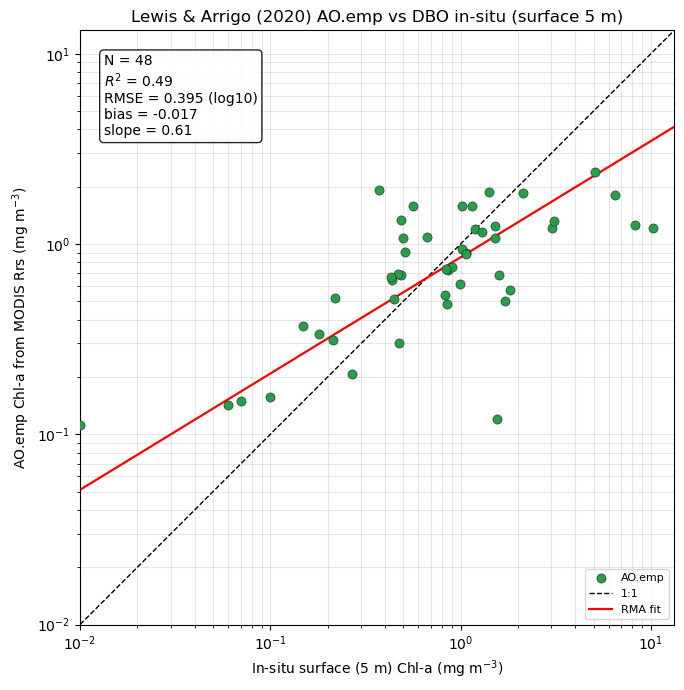

In [28]:
# ── Lewis & Arrigo (2020) AO.emp — MODIS, MBR = 443>488 / 547, 2nd order ────────────
AOEMP = dict(a=0.0957, b=-2.7973, c=0.6581)      # Table 2, MODIS columns
def ao_emp_chl(rrs443, rrs488, rrs547):
    b, g = np.maximum(np.asarray(rrs443, float), np.asarray(rrs488, float)), np.asarray(rrs547, float)
    with np.errstate(invalid="ignore", divide="ignore"):
        R = np.log10(b / g)
        chl = 10.0 ** (AOEMP["a"] + AOEMP["b"]*R + AOEMP["c"]*R**2)
    chl[~np.isfinite(R) | (b <= 0) | (g <= 0)] = np.nan
    return chl

matched["chl_aoemp"] = ao_emp_chl(matched["rrs443"], matched["rrs488"], matched["rrs547"])

sub = matched[(matched["chl_aoemp"] > 0) & (matched["chl_insitu"] > 0)
              & np.isfinite(matched["chl_aoemp"])]
st_oc = validation_stats(sub["chl_insitu"], sub["sat_chl"])       # NASA chlor_a, reference
st_ao = validation_stats(sub["chl_insitu"], sub["chl_aoemp"])     # AO.emp
print(pd.DataFrame({"NASA chlor_a": st_oc, "AO.emp": st_ao}).T
      [["N","R2","RMSE_log10","bias_log10","RMA_slope"]].round(3))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(sub["chl_insitu"], sub["chl_aoemp"], s=44, color="#2a9d4a",
           edgecolor="k", linewidth=.3, zorder=3, label="AO.emp")
lo = max(1e-2, min(sub["chl_insitu"].min(), sub["chl_aoemp"].min()) * 0.7)
hi = max(sub["chl_insitu"].max(), sub["chl_aoemp"].max()) * 1.3
xx = np.array([lo, hi]); ax.plot(xx, xx, "k--", lw=1, label="1:1", zorder=2)
if st_ao.get("N", 0) >= 3:
    s, b = st_ao["RMA_slope"], st_ao["RMA_intercept"]
    ax.plot(xx, 10 ** b * xx ** s, "r-", lw=1.6, label="RMA fit", zorder=2)
    ax.text(0.04, 0.96, f"N = {st_ao['N']}\n$R^2$ = {st_ao['R2']:.2f}\n"
            f"RMSE = {st_ao['RMSE_log10']:.3f} (log10)\nbias = {st_ao['bias_log10']:+.3f}\n"
            f"slope = {st_ao['RMA_slope']:.2f}", transform=ax.transAxes, va="top", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi), aspect="equal",
       xlabel="In-situ surface (5 m) Chl-a (mg m$^{-3}$)",
       ylabel="AO.emp Chl-a from MODIS Rrs (mg m$^{-3}$)",
       title="Lewis & Arrigo (2020) AO.emp vs DBO in-situ (surface 5 m)")
ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=.3, which="both")
plt.tight_layout(); fig.savefig(OUT_DIR / "aoemp_validation.png", dpi=150)


## Part D — AO.emp match-ups and the time-window sweep (Fig. S1)

In [30]:
# ── AO.emp-aware box extraction (Lewis & Arrigo 2020, MODIS 443>488/547, 2nd order) ──
RRS_BANDS = ["Rrs_443", "Rrs_488", "Rrs_547"]
AOEMP = dict(a=0.0957, b=-2.7973, c=0.6581)

def aoemp_from_rrs(r443, r488, r547):
    if not (np.isfinite(r443) and np.isfinite(r488) and np.isfinite(r547)) or r547 <= 0:
        return np.nan
    blue = max(r443, r488)
    if blue <= 0:
        return np.nan
    R = np.log10(blue / r547)
    return float(10.0 ** (AOEMP["a"] + AOEMP["b"]*R + AOEMP["c"]*R**2))

def open_l2(path):
    geo = xr.open_dataset(path, group="geophysical_data", engine="h5netcdf")
    nav = xr.open_dataset(path, group="navigation_data", engine="h5netcdf")
    chl   = geo["chlor_a"].values.astype("float64")
    flags = geo["l2_flags"].values.astype("int64")
    _fb = build_flag_bitmask(geo["l2_flags"], EXCLUDE_FLAGS)
    fbits = int(_fb[0] if isinstance(_fb, tuple) else _fb)
    rrs = {b: (geo[b].values.astype("float64") if b in geo.variables else np.full_like(chl, np.nan))
           for b in RRS_BANDS}
    latg = nav["latitude"].values.astype("float64")
    long = nav["longitude"].values.astype("float64")
    geo.close(); nav.close()
    return latg, long, chl, flags, fbits, rrs

def extract_matchup(lat0, lon0, latg, long, chl, flags, fbits, rrs=None):
    near = (np.abs(latg - lat0) < 0.25) & (np.abs(long - lon0) < 0.5)
    if not near.any():
        return {"status": "not_in_swath"}
    ii, jj = np.where(near)
    d = haversine_km(lat0, lon0, latg[ii, jj], long[ii, jj])
    k = int(np.argmin(d)); i0, j0, dmin = int(ii[k]), int(jj[k]), float(d[k])
    if dmin > MAX_PIX_DIST_KM:
        return {"status": "too_far", "dist_km": dmin}
    h = BOX_SIZE // 2
    if i0-h < 0 or j0-h < 0 or i0+h >= chl.shape[0] or j0+h >= chl.shape[1]:
        return {"status": "box_off_edge", "dist_km": dmin}
    sl = (slice(i0-h, i0+h+1), slice(j0-h, j0+h+1))
    cbox, fbox = chl[sl], flags[sl]
    valid = np.isfinite(cbox) & (cbox > 0) & ((fbox & fbits) == 0)
    n_box, n_valid = cbox.size, int(valid.sum())
    if n_valid <= MIN_VALID_FRAC * n_box:
        return {"status": "too_few_valid", "dist_km": dmin, "n_valid": n_valid}
    v = cbox[valid]; mean0, std0 = float(v.mean()), float(v.std(ddof=0))
    cv = std0/mean0 if mean0 > 0 else np.inf
    keep = np.abs(cbox - mean0) <= FILTER_SIGMA*std0
    sat = float(cbox[valid & keep].mean()) if (valid & keep).any() else mean0
    sat_aoemp = np.nan
    if rrs is not None:
        def _bm(b):
            vb = rrs[b][sl]; m = np.isfinite(vb) & valid
            return float(np.median(vb[m])) if m.any() else np.nan
        sat_aoemp = aoemp_from_rrs(_bm("Rrs_443"), _bm("Rrs_488"), _bm("Rrs_547"))
    status = "ok" if cv <= MAX_CV else "high_cv"
    return {"status": status, "sat_chl": sat, "sat_chl_aoemp": sat_aoemp,
            "cv": cv, "n_valid": n_valid, "dist_km": dmin}
print("AO.emp-aware machinery ready")


AO.emp-aware machinery ready


In [31]:
# ---- time-sweep config (the vars that live in the sweep notebook's CONFIG) ----
MAX_WINDOW_HOURS   = 72.0                              # widest +/- window to collect granules for
TIME_WINDOWS       = [3, 6, 9, 12, 18, 24, 36, 48, 72] # +/- hours to evaluate (all <= MAX_WINDOW_HOURS)
AGG                = "mean"                            # "mean" (avg passes within +/-T) or "nearest"
MAX_CANDIDATES     = 60                                # cap granules downloaded per station
REQUIRE_KNOWN_TIME = True                              # exclude date-only casts (needed for a TIME sweep)
RECOMPUTE          = False

# a TIME sweep must use only stations with a real clock time
insitu_ks = insitu[insitu["time_known"]].copy() if REQUIRE_KNOWN_TIME else insitu.copy()
print(f"{len(insitu_ks)} known-time stations for the sweep")


217 known-time stations for the sweep


In [32]:
# ===== Cell 2 (RUN THIS) — collect AO.emp candidates fresh, discard the poisoned cache =====
import pickle
CACHE_PKL = OUT_DIR / "matchup_cache_timesweep_aoemp.pkl"
FRESH = True                          # discard the empty cache from the earlier broken run
cache = {} if FRESH or not CACHE_PKL.exists() else pickle.load(open(CACHE_PKL, "rb"))

results_ao, n_cand, n_aoemp = [], 0, 0
for n, row in enumerate(insitu_ks.itertuples(index=False), 1):
    uid = row.uid
    if uid in cache and cache[uid].get("candidates"):
        results_ao.append(cache[uid]); n_cand += len(cache[uid]["candidates"]); continue
    lat0, lon0, t_is = row.lat, row.lon, row.datetime
    t0 = t_is - pd.Timedelta(hours=MAX_WINDOW_HOURS); t1 = t_is + pd.Timedelta(hours=MAX_WINDOW_HOURS)
    rec = {"uid": uid, "year": row.year, "station": row.station, "chl_insitu": row.chl_insitu,
           "status": "no_granule", "candidates": []}
    try:
        grans = earthaccess.search_data(short_name=MODIS_SHORT_NAME,
            temporal=(t0.strftime("%Y-%m-%dT%H:%M:%S"), t1.strftime("%Y-%m-%dT%H:%M:%S")),
            bounding_box=(lon0-BBOX_HALF_DEG, lat0-BBOX_HALF_DEG, lon0+BBOX_HALF_DEG, lat0+BBOX_HALF_DEG))
    except Exception as e:
        grans = []; rec["status"] = f"search_err:{str(e)[:40]}"
    if grans:
        grans = sorted(grans, key=lambda g: abs((granule_mid_time(g)-t_is).total_seconds()))[:MAX_CANDIDATES]
        cands = []
        for g in grans:
            gt = granule_mid_time(g); dt_h = (gt - t_is).total_seconds()/3600.0
            if abs(dt_h) > MAX_WINDOW_HOURS: continue
            try:
                path = earthaccess.download([g], str(GRANULE_CACHE))[0]
                m = extract_matchup(lat0, lon0, *open_l2(path))
            except Exception:
                continue
            if m.get("status") == "ok":
                cands.append({"dt_hours": dt_h, "sat_chl": m["sat_chl"],
                              "sat_chl_aoemp": m["sat_chl_aoemp"], "granule": g["umm"]["GranuleUR"]})
        rec["candidates"] = cands
        rec["status"] = "ok" if cands else "no_valid_box"
        n_cand += len(cands); n_aoemp += sum(1 for c in cands if np.isfinite(c["sat_chl_aoemp"]))
    cache[uid] = rec; results_ao.append(rec)
    if n % 10 == 0 or n == len(insitu_ks):
        pickle.dump(cache, open(CACHE_PKL, "wb"))
        nok = sum(1 for r in results_ao if r.get("candidates"))
        print(f"  {n}/{len(insitu_ks)} — {nok} stations w/ candidates | "
              f"{n_cand} granule-matchups, {n_aoemp} with finite AO.emp")
pickle.dump(cache, open(CACHE_PKL, "wb"))
recs_ao = [r for r in results_ao if r.get("candidates")]
print(f"\nDONE: {len(recs_ao)} stations w/ candidates; {n_aoemp}/{n_cand} granule-matchups have finite AO.emp")



QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

In [35]:
import pickle, numpy as np
CACHE_PKL = OUT_DIR / "matchup_cache_timesweep_aoemp.pkl"
cache = pickle.load(open(CACHE_PKL, "rb"))
recs_ao = [r for r in cache.values() if r.get("candidates")]

# sanity check so Cell 3 doesn't come back all-NaN
n_cand  = sum(len(r["candidates"]) for r in recs_ao)
n_aoemp = sum(1 for r in recs_ao for c in r["candidates"]
              if np.isfinite(c.get("sat_chl_aoemp", np.nan)))
print(f"loaded {len(cache)} records — {len(recs_ao)} stations w/ candidates | "
      f"{n_cand} granule-matchups, {n_aoemp} with finite AO.emp")


loaded 217 records — 80 stations w/ candidates | 148 granule-matchups, 148 with finite AO.emp


 window_h  N_stations  n_granule_matchups    R2  RMSE_log10  bias_log10
        3           2                   2   NaN         NaN         NaN
        6           2                   2   NaN         NaN         NaN
        9           8                   9 0.566       0.712      -0.146
       12          12                  15 0.579       0.608      -0.099
       18          18                  22 0.628       0.511      -0.081
       24          22                  29 0.648       0.479      -0.118
       36          32                  42 0.556       0.475      -0.115
       48          56                  87 0.351       0.533      -0.066
       72          80                 148 0.414       0.527      -0.084


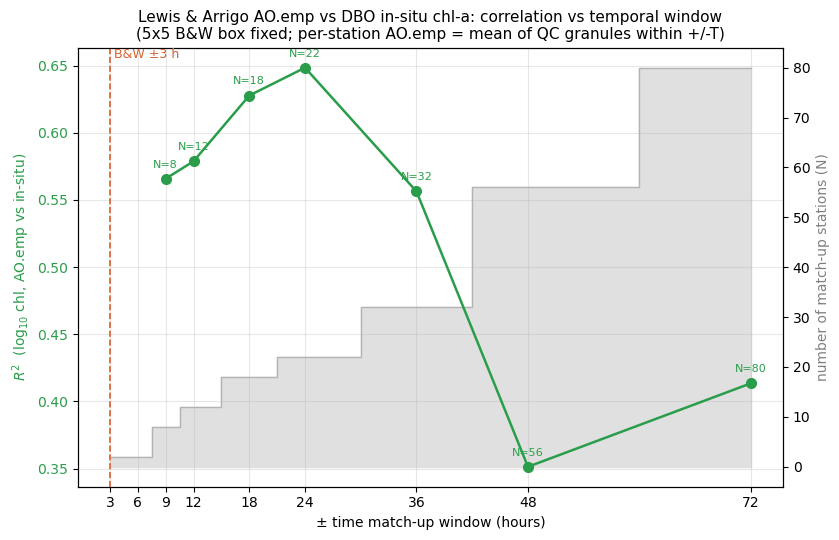

In [36]:
# ===== Cell 3 — AO.emp time-window sweep + figure =====
def sat_agg(cands, T, field):
    sel = [c for c in cands if abs(c["dt_hours"]) <= T
           and np.isfinite(c.get(field, np.nan)) and c[field] > 0]
    if not sel:
        return np.nan
    if AGG == "nearest":
        return min(sel, key=lambda c: abs(c["dt_hours"]))[field]
    return float(np.mean([c[field] for c in sel]))

rows = []
for T in TIME_WINDOWS:
    xs, ys, ng = [], [], 0
    for r in recs_ao:
        val = sat_agg(r["candidates"], T, "sat_chl_aoemp")
        if not np.isfinite(val):
            continue
        ng += sum(1 for c in r["candidates"] if abs(c["dt_hours"]) <= T
                  and np.isfinite(c.get("sat_chl_aoemp", np.nan)) and c["sat_chl_aoemp"] > 0)
        xs.append(r["chl_insitu"]); ys.append(val)
    st = validation_stats(xs, ys)
    rows.append({"window_h": T, "N_stations": st.get("N", 0), "n_granule_matchups": ng,
                 "R2": st.get("R2", np.nan), "RMSE_log10": st.get("RMSE_log10", np.nan),
                 "bias_log10": st.get("bias_log10", np.nan)})
sweep = pd.DataFrame(rows)
sweep.to_csv(OUT_DIR / "time_window_sweep_aoemp.csv", index=False)
print(sweep.round(3).to_string(index=False))

# ---- figure (AO.emp) ----
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax2 = ax.twinx()

# N behind (like the paper's image-count histogram), R2 in front
ax2.fill_between(sweep["window_h"], sweep["N_stations"], step="mid", color="0.88", zorder=1)
ax2.plot(sweep["window_h"], sweep["N_stations"], drawstyle="steps-mid", color="0.7", lw=1, zorder=1)

ax.plot(sweep["window_h"], sweep["R2"], "o-", color="#2a9d4a", ms=7, lw=1.8, zorder=3)
for x, y, nn in zip(sweep["window_h"], sweep["R2"], sweep["N_stations"]):
    if np.isfinite(y):
        ax.annotate(f"N={nn}", (x, y), textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=8, color="#2a9d4a")

ax.axvline(3, color="#d6602c", ls="--", lw=1.2, zorder=2)
ax.text(3, ax.get_ylim()[1], " B&W ±3 h", color="#d6602c", va="top", ha="left", fontsize=9)

ax.set_xlabel("± time match-up window (hours)")
ax.set_ylabel("$R^2$  (log$_{10}$ chl, AO.emp vs in-situ)", color="#2a9d4a")
ax2.set_ylabel("number of match-up stations (N)", color="0.5")
ax.tick_params(axis="y", labelcolor="#2a9d4a")
ax.set_xticks(TIME_WINDOWS)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)   # keep R2 line above the N band
ax.grid(alpha=0.3)
ax.set_title(f"Lewis & Arrigo AO.emp vs DBO in-situ chl-a: correlation vs temporal window\n"
             f"(5x5 B&W box fixed; per-station AO.emp = {AGG} of QC granules within +/-T)", fontsize=11)
plt.tight_layout()
fig.savefig(OUT_DIR / "time_window_sweep_aoemp.png", dpi=150)
plt.show()
